# 1. Data Loading and Inspection

Data NOAA yang digunakan masih dalam format mentah (raw), dimana sejumlah kolom berisi nilai gabungan yang perlu diuraikan (parsing) terlebih dahulu sebelum dapat digunakan untuk tahap analisis. Tahap ini bertujuan untuk memahami struktur data secara umum sebelum dilakukan proses pre-processing lebih lanjut. Kita belum memodifikasi bentuk data dan hanya ingin tahu berapa jumlah baris, kolom apa saja yang ada, di mana missing value berada, dan bagaimana pola interval waktunya

## 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb

from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

## 1.2 Load Dataset

Path dataset disesuaikan dengan lokasi penyimpanan pada perangkat

In [2]:
data_df = pd.read_csv('dataset/bmkg-jambi-year-24.csv')
data_df.head(5)

,STATION,DATE,SOURCE,LATITUDE,LONGITUDE,ELEVATION,NAME,REPORT_TYPE,CALL_SIGN,QUALITY_CONTROL,...,GA4,GA5,GE1,GF1,KA1,MA1,MD1,MW1,REM,EQD
0,96195099999,2024-01-01T00:00:00,4,-1.638017,103.644378,24.99,"SULTAN THAHA, ID",FM-12,99999,V020,...,NaN,NaN,"9,AGL ,+99999,+99999","08,99,1,05,1,99,9,00390,1,99,9,99,9","120,N,+0248,1","99999,9,10081,1","3,1,011,1,+999,9","61,1",SYN13096195 01456 83602 10250 20247 30081 4011...,Q01 003SCCGA3
1,96195099999,2024-01-01T03:00:00,4,-1.638017,103.644378,24.99,"SULTAN THAHA, ID",FM-12,99999,V020,...,NaN,NaN,"9,AGL ,+99999,+99999","08,99,1,05,1,99,9,00360,1,99,9,99,9",NaN,"99999,9,10092,1","9,9,011,1,+999,9","61,1",SYN08896195 21458 82805 10260 20249 30092 4012...,NaN
2,96195099999,2024-01-01T06:00:00,4,-1.638017,103.644378,24.99,"SULTAN THAHA, ID",FM-12,99999,V020,...,NaN,NaN,"9,AGL ,+99999,+99999","08,99,1,05,1,99,9,00360,1,99,9,99,9",NaN,"99999,9,10077,1","6,1,015,1,+999,9","61,1",SYN09496195 01460 83203 10268 20253 30077 4010...,NaN
3,96195099999,2024-01-01T09:00:00,4,-1.638017,103.644378,24.99,"SULTAN THAHA, ID",FM-12,99999,V020,...,NaN,NaN,"9,AGL ,+99999,+99999","07,99,1,04,1,99,9,00450,1,99,9,99,9",NaN,"99999,9,10057,1","6,1,020,1,+999,9",NaN,SYN09496195 22460 73106 10293 20244 30057 4008...,Q01 003SCCGA3
4,96195099999,2024-01-01T12:00:00,4,-1.638017,103.644378,24.99,"SULTAN THAHA, ID",FM-12,99999,V020,...,NaN,NaN,"9,AGL ,+99999,+99999","06,99,1,03,1,99,9,00450,1,99,9,99,9","240,M,+0295,1","99999,9,10071,1","3,1,014,1,+999,9","02,1",SYN10096195 11460 63205 10275 20248 30071 4010...,NaN


## 1.3 Check Data Structure

Pemeriksaan awal dilakukan untuk mengetahui jumlah baris, jumlah kolom, serta tipe data pada masing-masing kolom sebelum dilakukan pengolahan lebih lanjut

In [3]:
print(data_df.shape)

(3991, 34)


In [4]:
print(data_df.dtypes)

STATION              int64
DATE                   str
SOURCE               int64
LATITUDE           float64
LONGITUDE          float64
ELEVATION          float64
NAME                   str
REPORT_TYPE            str
CALL_SIGN            int64
QUALITY_CONTROL        str
WND                    str
CIG                    str
VIS                    str
TMP                    str
DEW                    str
SLP                    str
AA1                    str
AA2                    str
AA3                    str
AY1                    str
AY2                    str
GA1                    str
GA2                    str
GA3                    str
GA4                    str
GA5                    str
GE1                    str
GF1                    str
KA1                    str
MA1                    str
MD1                    str
MW1                    str
REM                    str
EQD                    str
dtype: object


## 1.5 Check Missing Values

Pemeriksaan dilakukan setelah proses penguraian untuk mengetahui proporsi data yang hilang pada masing-masing variabel, khususnya variabel visibility sebagai target prediksi

In [5]:
data_df.isna().sum()

STATION               0
DATE                  0
SOURCE                0
LATITUDE              0
LONGITUDE             0
ELEVATION             0
NAME                  0
REPORT_TYPE           0
CALL_SIGN             0
QUALITY_CONTROL       0
WND                   0
CIG                   0
VIS                   0
TMP                   0
DEW                   0
SLP                   0
AA1                3309
AA2                3771
AA3                3990
AY1                1659
AY2                1659
GA1                   1
GA2                  26
GA3                 749
GA4                3694
GA5                3864
GE1                   1
GF1                   0
KA1                3335
MA1                   0
MD1                1351
MW1                1659
REM                   0
EQD                2630
dtype: int64

## 1.6 Check Time Range and Interval Consistency

Kolom `DATE` dikonversi ke format datetime, kemudian diperiksa selisih waktu antar baris untuk mengetahui pola interval pencatatan data

In [6]:
data_df['DATE'] = pd.to_datetime(data_df['DATE'])
print(data_df['DATE'].min(), '-', data_df['DATE'].max())

2024-01-01 00:00:00 - 2024-12-31 23:00:00


In [7]:
time_diff = data_df['DATE'].diff()
print(time_diff.value_counts())

DATE
0 days 01:00:00     1964
0 days 03:00:00     1933
0 days 02:00:00       59
0 days 06:00:00       18
0 days 09:00:00        5
1 days 06:00:00        2
5 days 03:00:00        1
0 days 18:00:00        1
0 days 11:00:00        1
0 days 22:00:00        1
1 days 09:00:00        1
14 days 17:00:00       1
4 days 03:00:00        1
1 days 01:00:00        1
0 days 05:00:00        1
Name: count, dtype: int64


## 1.7 Identify Time Gaps

Ditemukan sejumlah selisih waktu yang tidak wajar antar baris data, termasuk satu jeda sepanjang 14 hari. Pemeriksaan lebih lanjut dilakukan untuk mengetahui lokasi tepat (rentang tanggal) dari jeda-jeda tersebut, guna memastikan periode tersebut diperhitungkan dengan benar pada tahap pembuatan fitur lag (lag feature) di kemudian hari.

In [8]:
gap_df = pd.DataFrame({
    'date_before': data_df['DATE'].shift(1),
    'date_after': data_df['DATE'],
    'gap': time_diff
})

In [9]:
large_gaps = gap_df[gap_df['gap'] > pd.Timedelta(hours=6)].sort_values('gap', ascending=False)
large_gaps

,date_before,date_after,gap
3106,2024-10-30 13:00:00,2024-11-14 06:00:00,14 days 17:00:00
685,2024-03-27 15:00:00,2024-04-01 18:00:00,5 days 03:00:00
3136,2024-11-17 21:00:00,2024-11-22 00:00:00,4 days 03:00:00
3105,2024-10-29 04:00:00,2024-10-30 13:00:00,1 days 09:00:00
912,2024-04-30 15:00:00,2024-05-01 21:00:00,1 days 06:00:00
1712,2024-08-11 18:00:00,2024-08-13 00:00:00,1 days 06:00:00
3285,2024-11-30 21:00:00,2024-12-01 22:00:00,1 days 01:00:00
3104,2024-10-28 06:00:00,2024-10-29 04:00:00,0 days 22:00:00
689,2024-04-02 03:00:00,2024-04-02 21:00:00,0 days 18:00:00
2092,2024-09-13 09:00:00,2024-09-13 20:00:00,0 days 11:00:00


Ditemukan 15 titik jeda waktu signifikan (labih dari 6 jam) sepanjang tahun 2024. Jeda paling ekstrem terjadi pada 30 Oktober hingga 14 November 2024 (14 hari 17 jam), yang bertepatan dengan periode akhir musim kemarau — periode yang secara klimatologis berpotensi memiliki kejadian visibility rendah akibat kabut asap kebakaran hutan dan lahan. Ketiadaan data pada periode krusial ini merupakan keterbatasan (limitation) yang perlu diungkapkan secara eksplisit pada bagian pembahasan laporan, mengingat hal ini dapat memengaruhi tingkat keparahan class imbalance yang teramati — kemungkinan sebagian disebabkan oleh kekosongan data pada periode rawan, bukan semata-mata karena kejadian visibility rendah yang memang jarang terjadi. Catatan ini juga menjadi acuan untuk pemeriksaan serupa pada dataset BMKG resmi setelah diterima.

# 2. Data Parsing and Encoding

Sejumlah kolom pada dataset NOAA, khususnya WND, VIS, TMP, dan DEW, masih berbentuk string gabungan yang memuat beberapa informasi sekaligus dalam satu sel. Tahap ini bertujuan menguraikan kolom-kolom tersebut menjadi variabel numerik yang dapat digunakan pada tahap analisis dan pemodelan selanjutnya.

## 2.1 Parse Compressed Columns (WND, VIS, TMP, DEW)

Kolom WND, VIS, TMP, dan DEW pada daset NOAA masih berbentuk string gabungan yang memuat beberapa informasi sekaligus. Pada tahap ini, kolom-kolom tersebut diuraikan menjadi variabel numerik yang siap digunakan, sekaligus mengonversi kode nilai hilang (missing value) menjadi NaN agar tidak dianggap sebagai data valid oleh model. 

`VIS`

In [10]:
data_df.loc[0:5, 'VIS']

0    006000,1,9,9
1    008000,1,9,9
2    010000,1,9,9
3    010000,1,9,9
4    010000,1,9,9
5    010000,1,9,9
Name: VIS, dtype: str

Penguraian VIS (Visibility) - variabel target

In [11]:
vis_split = data_df['VIS'].str.split(',', expand=True)
data_df['visibility_m'] = pd.to_numeric(vis_split[0], errors='coerce')
data_df.loc[data_df['visibility_m'] >= 999999, 'visibility_m'] = np.nan

`TMP`

In [12]:
data_df.loc[:5, 'TMP']

0    +0250,1
1    +0260,1
2    +0268,1
3    +0293,1
4    +0275,1
5    +0268,1
Name: TMP, dtype: str

Di dokumentasi format ISD, field suhu (TMP) disimpan dalam satuan 0.1°C, bukan langsung dalam °C. Jadi:

- +0250 itu artinya 25.0°C (250 dalam persepuluh derajat)
- +0260 → 26.0°C
- +0293 → 29.3°C

Ini dilakukan NOAA supaya mereka bisa nyimpen nilai desimal (kayak 25.3°C) tanpa perlu titik desimal di dalam string mentahnya — semua disimpan sebagai integer, lebih hemat storage dan konsisten formatnya buat parsing di sistem lama. Ini pattern umum banget di data format lawas/legacy meteorological data.

Penguraian TMP (suhu)

In [13]:
tmp_split = data_df['TMP'].str.split(',', expand=True)
data_df['temp_c'] = pd.to_numeric(tmp_split[0], errors='coerce') / 10
data_df.loc[data_df['temp_c'] >= 999, 'temp_c'] = np.nan

`DEW`

In [14]:
data_df.loc[:5, 'DEW']

0    +0247,1
1    +0249,1
2    +0253,1
3    +0244,1
4    +0248,1
5    +0249,1
Name: DEW, dtype: str

Penguraian Dew (titik embun)

In [15]:
dew_split = data_df['DEW'].str.split(',', expand=True)
data_df['dewpoint_c'] = pd.to_numeric(dew_split[0], errors='coerce') / 10
data_df.loc[data_df['dewpoint_c'] >= 999, 'dewpoint_c'] = np.nan

`WND`

In [16]:
data_df.loc[:5, 'WND']

0    360,1,N,0010,1
1    280,1,N,0026,1
2    320,1,N,0015,1
3    310,1,N,0031,1
4    320,1,N,0026,1
5    010,1,N,0010,1
Name: WND, dtype: str

Penguraian WND (arah dan kecepatan angin)

In [17]:
wind_split = data_df['WND'].str.split(',', expand=True)

data_df['wind_dir'] = pd.to_numeric(wind_split[0], errors='coerce')
data_df.loc[data_df['wind_dir'] >= 999, 'wind_dir'] = np.nan

data_df['wind_speed'] = pd.to_numeric(wind_split[3], errors='coerce') / 10
data_df.loc[data_df['wind_speed'] >= 9999, 'wind_speed'] = np.nan

In [18]:
gap_df = pd.DataFrame({
    'date_before': data_df['DATE'].shift(1),
    'date_after': data_df['DATE'],
    'gap': time_diff
})

In [19]:
large_gaps = gap_df[gap_df['gap'] > pd.Timedelta(hours=6)].sort_values('gap', ascending=False)
large_gaps

,date_before,date_after,gap
3106,2024-10-30 13:00:00,2024-11-14 06:00:00,14 days 17:00:00
685,2024-03-27 15:00:00,2024-04-01 18:00:00,5 days 03:00:00
3136,2024-11-17 21:00:00,2024-11-22 00:00:00,4 days 03:00:00
3105,2024-10-29 04:00:00,2024-10-30 13:00:00,1 days 09:00:00
912,2024-04-30 15:00:00,2024-05-01 21:00:00,1 days 06:00:00
1712,2024-08-11 18:00:00,2024-08-13 00:00:00,1 days 06:00:00
3285,2024-11-30 21:00:00,2024-12-01 22:00:00,1 days 01:00:00
3104,2024-10-28 06:00:00,2024-10-29 04:00:00,0 days 22:00:00
689,2024-04-02 03:00:00,2024-04-02 21:00:00,0 days 18:00:00
2092,2024-09-13 09:00:00,2024-09-13 20:00:00,0 days 11:00:00


## 2.2 Verify Parsing Result

Hasil penguraian diperiksa kembali untuk memastikan nilai-nilai numerik yang dihasilkan berada pada rentang yang wajar secara meteorologis.

In [20]:
data_df[['visibility_m', 'temp_c', 'dewpoint_c', 'wind_dir', 'wind_speed']].describe()

,visibility_m,temp_c,dewpoint_c,wind_dir,wind_speed
count,3991.000000,3990.000000,3991.00000,3661.000000,3991.000000
mean,7638.160862,27.922431,24.34445,186.634799,1.878276
std,2631.488429,2.748723,0.95087,101.426628,1.308812
min,100.000000,22.000000,20.60000,10.000000,0.000000
25%,5000.000000,25.700000,23.70000,120.000000,1.000000
50%,8000.000000,27.400000,24.40000,170.000000,1.500000
75%,10000.000000,30.000000,25.00000,290.000000,2.600000
max,10000.000000,36.000000,27.60000,360.000000,26.800000


---

In [21]:
data_df.columns.tolist()

['STATION',
 'DATE',
 'SOURCE',
 'LATITUDE',
 'LONGITUDE',
 'ELEVATION',
 'NAME',
 'REPORT_TYPE',
 'CALL_SIGN',
 'QUALITY_CONTROL',
 'WND',
 'CIG',
 'VIS',
 'TMP',
 'DEW',
 'SLP',
 'AA1',
 'AA2',
 'AA3',
 'AY1',
 'AY2',
 'GA1',
 'GA2',
 'GA3',
 'GA4',
 'GA5',
 'GE1',
 'GF1',
 'KA1',
 'MA1',
 'MD1',
 'MW1',
 'REM',
 'EQD',
 'visibility_m',
 'temp_c',
 'dewpoint_c',
 'wind_dir',
 'wind_speed']

In [22]:
data_df[['CIG', 'SLP', 'MW1', 'GA1', 'GA2', 'GA3', 'GA4', 'GA5', 'AA1', 'AA2', 'AA3']].head()

,CIG,SLP,MW1,GA1,GA2,GA3,GA4,GA5,AA1,AA2,AA3
0,"00390,1,C,N","10111,1","61,1","05,1,+00390,1,08,1","08,1,+03000,1,04,1","99,9,+03000,1,08,1",NaN,NaN,"03,0040,3,1","24,0110,3,1",NaN
1,"00360,1,C,N","10122,1","61,1","05,1,+00360,1,06,1","08,1,+03000,1,04,1",NaN,NaN,NaN,"03,0003,3,1",NaN,NaN
2,"00360,1,C,N","10107,1","61,1","05,1,+00360,1,06,1","08,1,+03000,1,04,1",NaN,NaN,NaN,"03,0005,3,1","06,0008,3,1",NaN
3,"03000,1,C,N","10087,1",NaN,"04,1,+00450,1,08,1","04,1,+03000,1,04,1","99,9,+01200,1,08,1",NaN,NaN,"03,0000,2,1",NaN,NaN
4,"03000,1,C,N","10101,1","02,1","03,1,+00450,1,06,1","03,1,+03000,1,04,1","99,9,+99999,9,00,1",NaN,NaN,"06,0000,2,1",NaN,NaN


---

## 2.3 Parse Additional Columns (SLP, AA1)

Kolom SLP (tekanan udara permukaan laut) dan AA1 (curah hujan) diuraikan dengan pola yang serupa dengan kolom-kolom sebelumnya, karena keduanya menyimpan nilai numerik dalam format terskala.

Parsing SLP (tekanan udara)

In [23]:
slp_split = data_df['SLP'].str.split(',', expand=True)
data_df['pressure_hpa'] = pd.to_numeric(slp_split[0], errors='coerce') / 10
data_df.loc[data_df['pressure_hpa'] >= 9999.9, 'pressure_hpa'] = np.nan

Parsing AA1 (curah hujan)

In [24]:
aa1_split = data_df['AA1'].str.split(',', expand=True)
data_df['precip_mm'] = pd.to_numeric(aa1_split[1], errors='coerce') / 10
data_df.loc[data_df['precip_mm'] >= 999.9, 'precip_mm'] = np.nan

In [25]:
data_df[['pressure_hpa', 'precip_mm']].describe()

,pressure_hpa,precip_mm
count,3991.000000,675.000000
mean,1009.531746,4.787556
std,1.979417,9.160646
min,1003.300000,0.000000
25%,1008.200000,0.100000
50%,1009.600000,0.800000
75%,1010.900000,5.000000
max,1016.400000,72.000000


Nilai precip_mm memiliki jumlah observasi yang jauh lebih sedikit (675 dari 3991 baris) dibandingkan variabel lain. Hal ini bukan mengindikasikan data yang rusak, melainkan karena kolom AA1 pada data mentah NOAA hanya terisi ketika hujan benar-benar tercatat pada periode observasi tersebut. Dengan demikian, nilai kosong (NaN) pada precip_mm kemungkinan besar merepresentasikan kondisi "tidak terjadi hujan", bukan data yang hilang akibat kegagalan pencatatan. Perlakuan ini akan memengaruhi strategi penanganan nilai kosong pada Tahap 4 (Preprocessing).

# 3. Exploratory Data Analysis (EDA)

Tahap ini bertujuan untuk memahami karakteristik data secara lebih mendalam melalui visualisasi dan analisis statistik deskriptif, sebagai dasar pengambilan keputusan pada tahap preprocessing dan feature engineering selanjutnya.

## 3.1 Visibility Distribution

Distribusi variabel target (visibility) diperiksa untuk mengetahui sebaran nilai secara umum, sekaligus menjadi dasar awal dalam menentukan batas (threshold) kategori pada tahap pendefinisian target klasifikasi.

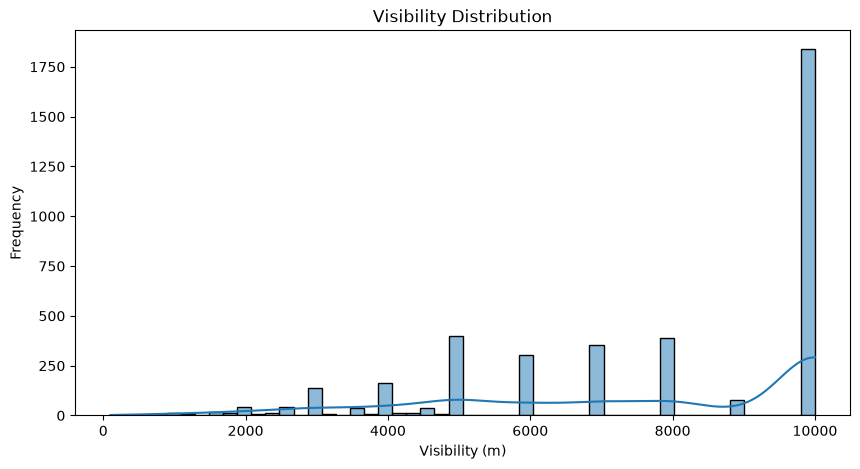

In [26]:
plt.figure(figsize=(10,5))

sns.histplot(data_df['visibility_m'], bins=50, kde=True)
plt.title('Visibility Distribution')
plt.xlabel('Visibility (m)')
plt.ylabel('Frequency')

plt.show()

In [27]:
data_df[['visibility_m']].describe()

,visibility_m
count,3991.000000
mean,7638.160862
std,2631.488429
min,100.000000
25%,5000.000000
50%,8000.000000
75%,10000.000000
max,10000.000000


**Analisis Distribusi**

- Median (8000 m) jauh lebih tinggi dari mean (7638 m) dan skewed ke arah kiri (nilai rendah lebih jarang tapi menarik mean turun) — ini pola klasik data visibility, di mana kondisi cerah/normal itu dominan, sementara kejadian visibility rendah itu minoritas
- Q1 (25%) = 5000 m — artinya bahkan di kuartil bawah pun visibility masih tergolong cukup baik
- Max = 10.000 m, dan kemungkinan besar ini nilai yang di-cap (banyak sensor NOAA emang capped di 10 km, jadi visibility 10 km ke atas semua dicatat sebagai 10000) — ini penting dicatat, karena artinya kita gak tau seberapa jauh visibility sebenarnya kalau udah di atas 10 km, tapi untungnya buat tujuan proyek ini (deteksi visibility rendah) itu gak masalah
- Min = 100 m — konfirmasi ada kejadian ekstrem rendah yang tercatat

Ini sudah mengonfirmasi dugaan awal: **class imbalance nyata ada**, karena median dan Q1 aja udah di atas 5000 m, sementara nilai rendah (yang jadi fokus prediksi) itu minoritas.

## 3.2 Proportion of Low-Visibility Events

Mengingat tujuan utama proyek adalah mendeteksi kejadian visibility rendah, perlu diketahui secara eksplisit seberapa besar proporsi kejadian tersebut dibandingkan kondisi normal. Ambang batas sementara digunakan di sini semata untuk keperluan eksplorasi awal, bukan definisi final kategori.

In [28]:
thresholds = [1000, 3000, 5000]

for t in thresholds:
    pct = (data_df['visibility_m'] < t).mean() * 100
    print(f'Proporsi visibility < {t} m: {pct:.2f}%')

Proporsi visibility < 1000 m: 0.50%
Proporsi visibility < 3000 m: 4.86%
Proporsi visibility < 5000 m: 15.64%


## 3.3 Correlation Between Variables

Analisis korelasi dilakukan untuk melihat hubungan linear antara visibility dengan variabel meteorologis lain, sebagai indikasi awal variabel mana yang berpotensi menjadi prediktor kuat.

In [29]:
numeric_cols = ['visibility_m', 'temp_c', 'dewpoint_c', 'wind_dir', 'wind_speed', 'pressure_hpa', 'precip_mm']
corr = data_df[numeric_cols].corr()

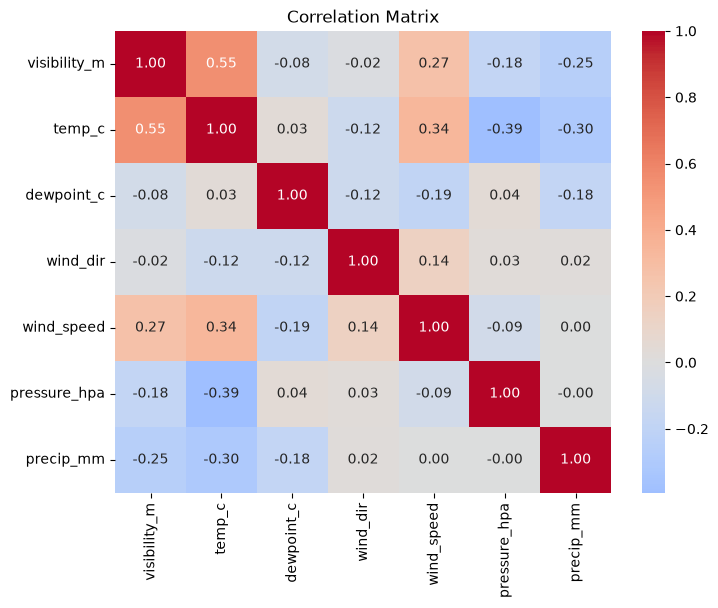

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')

plt.show()

**Insight**

Variabel temp_c menunjukkan korelasi linear positif terkuat terhadap visibility_m (0.55), diikuti oleh wind_speed (0.27). Variabel precip_mm dan pressure_hpa menunjukkan korelasi negatif lemah, sesuai ekspektasi teoritis bahwa curah hujan tinggi dan tekanan rendah berkaitan dengan cuaca buruk. Menariknya, dewpoint_c secara mentah menunjukkan korelasi yang sangat lemah (-0.08) terhadap visibility, meskipun secara teori titik embun berperan penting dalam pembentukan kabut. Hal ini memperkuat alasan pembuatan fitur turunan dew point depression (selisih suhu dan titik embun) pada tahap feature engineering, karena kabut umumnya terbentuk ketika suhu udara mendekati titik embun (selisih kecil), bukan berdasarkan nilai titik embun absolut. Secara keseluruhan, tidak ada variabel dengan korelasi linear yang sangat kuat (>0.6) terhadap visibility, yang mendukung pemilihan model berbasis pohon keputusan (tree-based) yang mampu menangkap hubungan non-linear dan interaksi antar variabel.

## 3.4 Monthly Pattern of Visibility

Pola bulanan diperiksa untuk mengetahui apakah terdapat variasi musiman pada visibility, mengingat wilayah Jambi memiliki kecenderungan penurunan visibility pada periode tertentu akibat faktor kabut asap kebakaran hutan dan lahan.

In [31]:
data_df['month'] = data_df['DATE'].dt.month

monthly_vis = data_df.groupby('month')['visibility_m'].agg(['mean', 'median', 'min'])
print(monthly_vis)

              mean   median     min
month                              
1      7984.210526  10000.0  1000.0
2      7162.770563   8000.0   500.0
3      7538.647343   8000.0   200.0
4      7590.748899   9000.0   700.0
5      7758.227848   8000.0  1500.0
6      7138.396624   8000.0  1000.0
7      7154.771784   7000.0  1200.0
8      7643.404255   8000.0   200.0
9      7613.375796   8000.0   100.0
10     7608.116883   8000.0   300.0
11     7874.301676  10000.0   900.0
12     7996.175637  10000.0   500.0


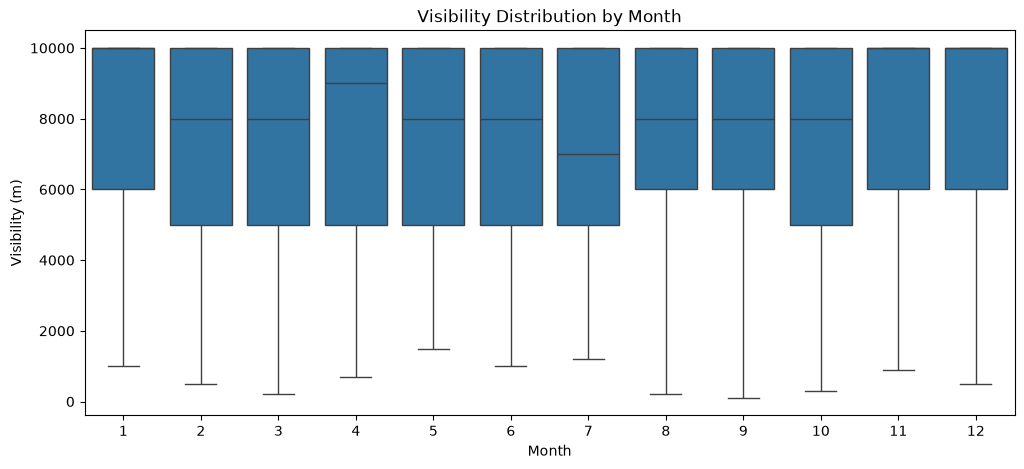

In [32]:
plt.figure(figsize=(12, 5))

sns.boxplot(x='month', y='visibility_m', data=data_df)
plt.title('Visibility Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Visibility (m)')

plt.show()

Pola visibility bulanan menunjukkan median yang relatif konsisten di sebagian besar bulan (sekitar 8000 m), dengan pengecualian bulan April yang cenderung lebih baik (median ~9000 m) dan bulan Juli yang sedikit lebih rendah (median ~7000 m). Yang menarik, nilai minimum (ujung whisker bawah) yang rendah muncul hampir merata di sepanjang tahun, bukan terkonsentrasi khusus pada periode musim kemarau (Agustus-Oktober) seperti yang diperkirakan sebelumnya berdasarkan pengetahuan umum mengenai kabut asap kebakaran hutan dan lahan di Sumatera. Pola ini kemungkinan dipengaruhi oleh keterbatasan data, khususnya jeda waktu 14 hari yang teridentifikasi pada Tahap 1 (30 Oktober–14 November), yang menghilangkan sebagian periode puncak musim kemarau dari dataset. Dengan demikian, pola musiman yang teramati pada dataset NOAA ini kemungkinan tidak sepenuhnya merepresentasikan kondisi aktual, dan perlu diperiksa kembali setelah data BMKG resmi diperoleh.

## 3.5 Hourly Pattern of Visibility

Pemeriksaan pola berdasarkan jam observasi dilakukan untuk mengetahui apakah kejadian visibility rendah cenderung terjadi pada waktu-waktu tertentu dalam sehari. Hal ini relevan mengingat kabut radiasi (radiation fog) secara umum terbentuk pada dini hari hingga pagi hari, saat suhu udara berada pada titik terendah dan kelembapan relatif tinggi.

In [33]:
data_df['hour'] = data_df['DATE'].dt.hour

hourly_vis = data_df.groupby('hour')['visibility_m'].agg(['mean', 'median', 'min'])
print(hourly_vis)

             mean   median     min
hour                              
0     4231.831832   4000.0   100.0
1     6855.421687   7000.0  1800.0
2     8014.285714   8000.0  3000.0
3     8832.732733  10000.0  1000.0
4     9449.438202  10000.0  5000.0
5     9522.727273  10000.0  6000.0
6     9566.964286  10000.0   200.0
7     9632.926829  10000.0   300.0
8     9193.975904  10000.0  1400.0
9     9236.036036  10000.0   700.0
10    9004.878049  10000.0  1800.0
11    7913.414634   8000.0   700.0
12    7961.818182   8000.0   700.0
13    7967.469880   8000.0  3000.0
14    7956.626506   8000.0  2500.0
15    7794.879518   8000.0  1700.0
16    7593.827160   8000.0  2500.0
17    7060.714286   7000.0   600.0
18    6877.811550   7000.0   500.0
19    6593.975904   6000.0   500.0
20    6468.674699   6000.0  1700.0
21    5920.307692   5000.0   200.0
22    6245.348837   5500.0  1000.0
23    5100.000000   4500.0   200.0


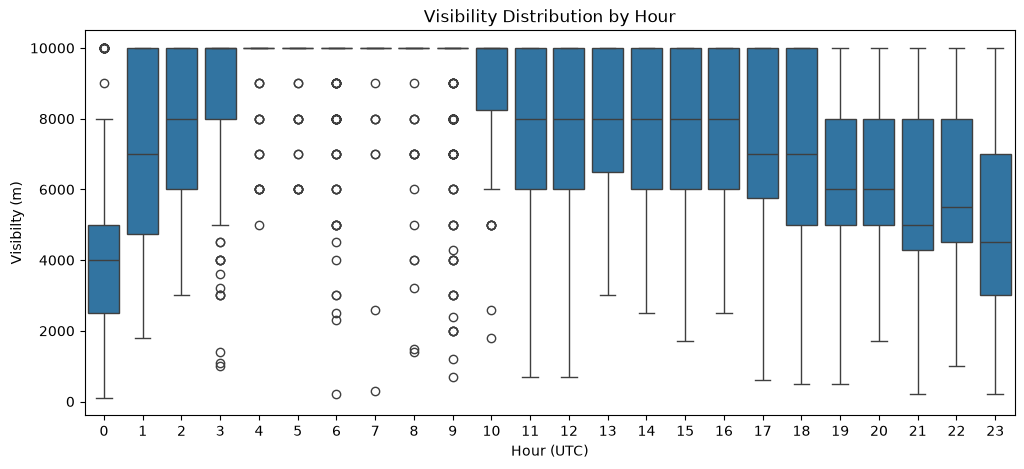

In [34]:
plt.figure(figsize=(12, 5))

sns.boxplot(x='hour', y='visibility_m', data=data_df)
plt.title('Visibility Distribution by Hour')
plt.xlabel('Hour (UTC)')
plt.ylabel('Visibilty (m)')

plt.show()

Setelah dikonversi ke waktu lokal (WIB = UTC+7), pola harian visibility menunjukkan siklus diurnal yang sangat konsisten dengan karakteristik kabut radiasi (radiation fog). Visibility terendah terjadi pada pukul 06:00–07:00 WIB (median 4000–4500 m, dengan nilai minimum absolut mencapai 100 m), bertepatan dengan waktu menjelang matahari terbit ketika suhu udara berada pada titik terendah dan kelembapan relatif tertinggi akibat pendinginan radiatif sepanjang malam. Visibility kemudian meningkat tajam pada pukul 08:00–10:00 WIB dan mencapai kondisi optimal (median 10.000 m) pada rentang pukul 10:00–16:00 WIB, sejalan dengan pemanasan permukaan oleh matahari yang menguapkan kabut dan menstabilkan atmosfer. Pola ini jauh lebih tegas dibandingkan pola musiman (bulanan) yang teramati sebelumnya, mengindikasikan bahwa variabel jam observasi (hour) berpotensi menjadi prediktor yang sangat kuat, dan bahwa kabut radiasi pagi hari kemungkinan merupakan fenomena dominan pada dataset ini dibandingkan sinyal kabut asap musiman.

# 4. Preprocessing

Tahap ini bertujuan untuk menangani nilai kosong (missing values) pada masing-masing variabel berdasarkan karakteristik dan penyebabnya, sebagaimana telah diidentifikasi pada tahap eksplorasi data sebelumnya. Strategi penanganan disesuaikan per variabel, mengingat tidak semua nilai kosong memiliki penyebab dan makna yang sama.

## 4.1 Convert Timestamp to Local Time (WIB)

Kolom DATE pada data mentah NOAA tercatat dalam zona waktu UTC. Konversi ke waktu lokal (WIB, UTC+7) dilakukan terlebih dahulu agar fitur berbasis waktu yang akan dibangun pada tahap selanjutnya (khususnya jam observasi) merepresentasikan kondisi waktu yang sesuai dengan siklus diurnal aktual di lokasi pengamatan.

In [35]:
data_df['DATE_WIB'] = data_df['DATE'] + pd.Timedelta(hours=7)
data_df[['DATE', 'DATE_WIB']].head()

,DATE,DATE_WIB
0,2024-01-01 00:00:00,2024-01-01 07:00:00
1,2024-01-01 03:00:00,2024-01-01 10:00:00
2,2024-01-01 06:00:00,2024-01-01 13:00:00
3,2024-01-01 09:00:00,2024-01-01 16:00:00
4,2024-01-01 12:00:00,2024-01-01 19:00:00


## 4.2 Review Missing Value

Sebelum menentukan strategi penanganan, dilakukan peninjauan ulang terhadap proporsi nilai kosong pada seluruh variabel numerik yang telah diuraikan.

In [36]:
missing_summary = data_df[['visibility_m', 'temp_c', 'dewpoint_c', 'wind_dir', 'wind_speed', 'pressure_hpa', 'precip_mm']].isna().sum()
missing_pct = (missing_summary / len(data_df)) * 100

print(pd.DataFrame({
    'missing_count': missing_summary,
    'missing_pct': missing_pct.round(2)
}))

              missing_count  missing_pct
visibility_m              0         0.00
temp_c                    1         0.03
dewpoint_c                0         0.00
wind_dir                330         8.27
wind_speed                0         0.00
pressure_hpa              0         0.00
precip_mm              3316        83.09


## 4.3 Inversitage Wind Direction Missing Pattern

In [37]:
data_df.loc[data_df['wind_dir'].isna(), ['DATE', 'wind_dir', 'wind_speed', 'WND']].head()

,DATE,wind_dir,wind_speed,WND
13,2024-01-02 15:00:00,NaN,0.0,"999,9,C,0000,1"
18,2024-01-03 06:00:00,NaN,0.0,"999,9,C,0000,1"
23,2024-01-03 21:00:00,NaN,0.0,"999,9,C,0000,1"
29,2024-01-04 15:00:00,NaN,0.0,"999,9,C,0000,1"
47,2024-01-06 21:00:00,NaN,0.0,"999,9,C,0000,1"


In [38]:
data_df.loc[data_df['wind_dir'].isna(), 'wind_speed'].value_counts()

wind_speed
0.0    330
Name: count, dtype: int64

Pemeriksaan lebih lanjut menunjukkan bahwa seluruh nilai kosong pada wind_dir berkorespondensi dengan wind_speed = 0 (kondisi angin kalem/calm wind). Berdasarkan konvensi pelaporan meteorologi, arah angin memang tidak terdefinisikan secara fisik ketika tidak terdapat pergerakan angin. Dengan demikian, nilai kosong pada wind_dir tidak dikategorikan sebagai missing value akibat kegagalan pencatatan, melainkan representasi dari kondisi angin kalem. Strategi imputasi menggunakan interpolasi tidak tepat diterapkan pada kasus ini; sebagai gantinya, representasi khusus akan diberikan pada tahap cyclic encoding (Tahap 5), di mana komponen sin dan cos untuk kondisi calm wind diberi nilai nol untuk merepresentasikan ketiadaan arah yang valid.

## 4.4 Handle Missing Value in temp_c

Nilai kosong pada temp_c hanya terjadi pada satu baris data (0,03%), sehingga penanganan dilakukan menggunakan interpolasi linear berbasis urutan waktu, mengingat data bersifat time series dan perubahan suhu antar observasi yang berdekatan cenderung bersifat kontinu.

In [39]:
data_df.loc[data_df['temp_c'].isna(), ['DATE', 'temp_c', 'TMP']]

,DATE,temp_c,TMP
1634,2024-08-01 21:00:00,NaN,"+9999,9"


In [40]:
data_df = data_df.sort_values('DATE_WIB').reset_index(drop=True)
data_df['temp_c'] = data_df['temp_c'].interpolate(method='linear')

print(data_df['temp_c'].isna().sum())

0


## 4.5 Handle Missing Value in precip_mm

Nilai kosong pada precip_mm merepresentasikan kondisi tidak terjadi hujan pada periode observasi tersebut, sebagaimana telah dibahas pada Tahap 2. Oleh karena itu, nilai kosong diisi dengan 0, bukan menggunakan metode imputasi statistik seperti mean atau median.

In [41]:
data_df['precip_mm'] = data_df['precip_mm'].fillna(0)

print('Missing Count: ', data_df['precip_mm'].isna().sum())
data_df['precip_mm'].describe()

Missing Count:  0


count    3991.000000
mean        0.809722
std         4.171004
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        72.000000
Name: precip_mm, dtype: float64

## 4.6 Verify All Missing Value Handled

Peninjauan akhir dilakukan untuk memastikan seluruh nilai kosong pada variabel numerik utama telah tertangani, kecuali wind_dir yang penanganannya ditunda hingga Tahap 5 (cyclic encoding).

In [42]:
final_check = data_df[['visibility_m', 'temp_c', 'dewpoint_c', 'wind_dir', 'wind_speed', 'pressure_hpa', 'precip_mm']].isna().sum()
print(final_check)

visibility_m      0
temp_c            0
dewpoint_c        0
wind_dir        330
wind_speed        0
pressure_hpa      0
precip_mm         0
dtype: int64


# 5. Feature Engineering

Tahap ini bertujuan untuk membangun variabel turunan (derived features) yang merepresentasikan pola-pola fisik dan temporal yang telah teridentifikasi pada tahap eksplorasi data, guna meningkatkan kemampuan model dalam mengenali kondisi yang berkaitan dengan visibility rendah.

## 5.1 Cyclic Encoding for Wind Direction

`wind_dir` merupakan variabel sirkular (0° dan 360° merepresentasikan arah yang sama), sehingga tidak tepat diperlakukan sebagai variabel linear biasa. Encoding dilakukan menggunakan transformasi sinus dan kosinus agar kedekatan antar arah tetap terepresentasi dengan benar oleh model. Untuk kondisi angin kalem (calm wind), di mana arah tidak terdefinisikan secara fisik, komponen sin dan cos diberi nilai nol.

**Konversi derajat ke radian, lalu sin/cos**

In [43]:
data_df['wind_dir_sin'] = np.sin(np.deg2rad(data_df['wind_dir']))
data_df['wind_dir_cos'] = np.cos(np.deg2rad(data_df['wind_dir']))

**Kondisi calm wind (wind_dir Nan karena wind_speed=0), set sin/cos=0**

In [44]:
calm_mask = data_df['wind_dir'].isna()
data_df.loc[calm_mask, 'wind_dir_sin'] = 0
data_df.loc[calm_mask, 'wind_dir_cos'] = 0

**Verifikasi**

In [45]:
print(data_df[['wind_dir', 'wind_dir_sin', 'wind_dir_cos']].isna().sum())
data_df[['wind_dir', 'wind_dir_sin', 'wind_dir_cos']].head(15)

wind_dir        330
wind_dir_sin      0
wind_dir_cos      0
dtype: int64


,wind_dir,wind_dir_sin,wind_dir_cos
0,360.0,-2.449294e-16,1.000000
1,280.0,-9.848078e-01,0.173648
2,320.0,-6.427876e-01,0.766044
3,310.0,-7.660444e-01,0.642788
4,320.0,-6.427876e-01,0.766044
5,10.0,1.736482e-01,0.984808
6,280.0,-9.848078e-01,0.173648
7,310.0,-7.660444e-01,0.642788
8,320.0,-6.427876e-01,0.766044
9,360.0,-2.449294e-16,1.000000


## 5.2 Calculate Dew Point Depression

**Dew point depression**, yaitu <u>*selisih antara suhu udara dan titik embun*</u>, merupakan indikator penting dalam mengidentifikasi potensi pembentukan kabut. Semakin kecil nilai selisih ini, semakin dekat kondisi udara terhadap titik saturasi, yang meningkatkan kemungkinan terbentuknya kabut atau penurunan visibility.

**Dew point** (titik embun) itu suhu di mana udara harus didinginkan sampai jadi **jenuh/saturated** (kelembapan relatif = 100%), sampai uap air mulai mengembun jadi titik-titik air (contoh: embun di rumput pagi hari, atau kabut).

Jadi **dew point depression** itu ngukur **seberapa "jauh" suhu udara saat ini dari titik jenuhnya**:
- **Depression kecil** (temp dan dew point deket) → udara hampir jenuh, kelembapan tinggi, kondisi mendekati pembentukan kabut/embun
- **Depression besar** (temp dan dew point jauh) → udara masih jauh dari jenuh, kelembapan relatif rendah, kecil kemungkinan kabut

```
Temp = 25°C, Dew Point = 24°C  →  Depression = 1°C   (udara SANGAT lembap, dekat titik jenuh)
Temp = 30°C, Dew Point = 15°C  →  Depression = 15°C  (udara kering, jauh dari jenuh)
```

In [46]:
data_df['dewpoint_depression'] = data_df['temp_c'] - data_df['dewpoint_c']
data_df['dewpoint_depression'].describe()

count    3991.000000
mean        3.577299
std         2.877266
min         0.000000
25%         1.200000
50%         2.600000
75%         5.500000
max        14.000000
Name: dewpoint_depression, dtype: float64

**Analisis**

- Semua nilai dewpoint_depression ≥ 0 (min = 0.0) — ini secara fisik benar, karena dew point tidak pernah melebihi suhu udara (kalau sampai negatif, itu tandanya ada error data)
- Rentang 0 – 14°C, dengan median 2.6°C — masuk akal untuk iklim tropis lembap

**Catatan**

Perbandingan nilai dewpoint_depression antara observasi acak dan observasi dengan visibility rendah (<5000 m) menunjukkan pola yang jelas: pada kondisi visibility rendah, nilai dewpoint_depression cenderung mengelompok pada angka kecil (0,3–2,9°C), mengindikasikan kondisi udara yang mendekati titik saturasi. Temuan ini memperkuat justifikasi pembuatan fitur turunan ini, mengingat variabel dewpoint_c secara mentah menunjukkan korelasi linear yang sangat lemah terhadap visibility (Tahap 3.3), namun pola hubungannya menjadi lebih jelas setelah ditransformasikan dalam bentuk selisih terhadap suhu udara.

In [47]:
data_df[['temp_c', 'dewpoint_c', 'dewpoint_depression', 'visibility_m']].head(10)

,temp_c,dewpoint_c,dewpoint_depression,visibility_m
0,25.0,24.7,0.3,6000.0
1,26.0,24.9,1.1,8000.0
2,26.8,25.3,1.5,10000.0
3,29.3,24.4,4.9,10000.0
4,27.5,24.8,2.7,10000.0
5,26.8,24.9,1.9,10000.0
6,25.8,24.4,1.4,10000.0
7,25.2,24.4,0.8,6000.0
8,24.8,24.0,0.8,5000.0
9,28.8,24.7,4.1,10000.0


In [48]:
data_df.loc[data_df['visibility_m'] < 5000, ['temp_c', 'dewpoint_c', 'dewpoint_depression', 'visibility_m']].head(10)

,temp_c,dewpoint_c,dewpoint_depression,visibility_m
23,25.2,24.6,0.6,4100.0
24,25.2,24.7,0.5,4500.0
32,24.9,24.4,0.5,4000.0
43,27.3,24.4,2.9,4000.0
48,24.8,24.3,0.5,2000.0
62,24.7,24.3,0.4,3000.0
63,24.6,24.3,0.3,3000.0
72,25.4,22.8,2.6,1000.0
88,25.7,24.5,1.2,4000.0
103,25.2,24.1,1.1,4500.0


## 5.3 Extract Time Features from `DATE_WIB`

Fitur waktu diekstraksi dari DATE_WIB (waktu lokal) untuk menangkap pola diurnal yang telah teridentifikasi pada tahap eksplorasi data, khususnya pola kabut radiasi yang memuncak pada dini hari menjelang pagi. Variabel jam (hour) bersifat sirkular (jam 23 dan jam 0 berdekatan secara waktu), sehingga turut dilakukan cyclic encoding serupa dengan wind_dir.

**Ekstraksi Fitur Waktu Dasar**

In [49]:
data_df['hour'] = data_df['DATE_WIB'].dt.hour
data_df['month'] = data_df['DATE_WIB'].dt.month
data_df['dayofyear'] = data_df['DATE_WIB'].dt.dayofyear

**Cyclic Encoding untuk Hour (Periode 24 Jam)**

In [50]:
data_df['hour_sin'] = np.sin(2 * np.pi * data_df['hour'] / 24)
data_df['hour_cos'] = np.cos(2 * np.pi * data_df['hour'] / 24)

**Cyclic Encoding untuk Month (Periode 12 Bulan)**

In [51]:
data_df['month_sin'] = np.sin(2 * np.pi * data_df['month'] / 12)
data_df['month_cos'] = np.cos(2 * np.pi * data_df['month'] / 12)

In [52]:
data_df[['DATE_WIB', 'hour', 'hour_sin', 'hour_cos', 'month', 'month_sin', 'month_cos']].head(5)

,DATE_WIB,hour,hour_sin,hour_cos,month,month_sin,month_cos
0,2024-01-01 07:00:00,7,0.965926,-0.258819,1,0.5,0.866025
1,2024-01-01 10:00:00,10,0.500000,-0.866025,1,0.5,0.866025
2,2024-01-01 13:00:00,13,-0.258819,-0.965926,1,0.5,0.866025
3,2024-01-01 16:00:00,16,-0.866025,-0.500000,1,0.5,0.866025
4,2024-01-01 19:00:00,19,-0.965926,0.258819,1,0.5,0.866025


## 5.4 Flag for Fog-Prone Hours (Optional Feature)

Berdasarkan temuan pada Tahap 3.6, visibility terendah secara konsisten terjadi pada rentang pukul 04:00–08:00 WIB. Sebuah fitur biner ditambahkan untuk menandai observasi yang berada pada rentang waktu rawan kabut radiasi tersebut, sebagai representasi eksplisit dari pola yang telah teridentifikasi.

In [53]:
hourly_median = data_df.groupby('hour')['visibility_m'].median()
hourly_median

hour
0      7000.0
1      7000.0
2      6000.0
3      6000.0
4      5000.0
5      5500.0
6      4500.0
7      4000.0
8      7000.0
9      8000.0
10    10000.0
11    10000.0
12    10000.0
13    10000.0
14    10000.0
15    10000.0
16    10000.0
17    10000.0
18     8000.0
19     8000.0
20     8000.0
21     8000.0
22     8000.0
23     8000.0
Name: visibility_m, dtype: float64

In [54]:
fog_prone_hours = hourly_median[hourly_median < 6000].index.tolist()
print('Jam-jam rawan kabut: ', fog_prone_hours)

Jam-jam rawan kabut:  [4, 5, 6, 7]


Berdasarkan hasil perhitungan median visibility per jam pada data, rentang jam 04:00–07:00 WIB teridentifikasi sebagai periode dengan visibility median di bawah 6000 m, sehingga ditetapkan sebagai jam rawan kabut radiasi. Sebagai catatan, terdapat sedikit perbedaan dengan informasi dari pihak operasional yang menyebutkan kondisi visibility umumnya mulai membaik pada pukul 09:00 WIB. Perbedaan ini kemungkinan disebabkan oleh cakupan data yang terbatas pada satu tahun observasi (2024), serta kemungkinan variasi musiman yang tidak sepenuhnya tertangkap. Hal ini menjadi salah satu poin yang perlu didiskusikan lebih lanjut dengan pihak forecaster operasional.

In [55]:
data_df['is_fog_prone_hour'] = data_df['hour'].isin(fog_prone_hours).astype(int)
print(data_df['is_fog_prone_hour'].value_counts())

is_fog_prone_hour
0    3163
1     828
Name: count, dtype: int64


## 5.5 Create Lag Features (with Gap Awareness)

Fitur lag dibuat untuk merepresentasikan nilai visibility pada observasi-observasi sebelumnya, mengingat kondisi visibility umumnya bersifat persisten dan berubah secara bertahap. Mengingat teridentifikasinya sejumlah jeda waktu signifikan pada Tahap 1, pembuatan fitur lag perlu memperhitungkan jarak waktu aktual antar observasi, agar nilai lag tidak dihitung melintasi periode yang terputus jauh.

Hitung selisih waktu aktual antar baris berurutan

In [56]:
data_df['time_gap_hours'] = data_df['DATE_WIB'].diff().dt.total_seconds() / 3600

Buat lag feature untuk 1, 2, dan 3 observasi sebelumnya

In [57]:
for lag in [1, 2, 3]:
    data_df[f'visibility_lag{lag}'] = data_df['visibility_m'].shift(lag)

Cek cumulative time gap untuk tiap lag (jarak waktu aktual, bukan jumlah baris)

In [58]:
data_df['cum_gap_lag1'] = data_df['time_gap_hours']
data_df['cum_gap_lag2'] = data_df['time_gap_hours'] + data_df['time_gap_hours'].shift(1)
data_df['cum_gap_lag3'] = data_df['time_gap_hours'] + data_df['time_gap_hours'].shift(1) + data_df['time_gap_hours'].shift(2)

Set lag jadi NaN jika jarak waktu aktual terlalu jauh (lebih dari 9 jam untuk lag3)

In [59]:
max_valid_gap = 9
data_df.loc[data_df['cum_gap_lag1'] > 3, 'visibility_lag1'] = np.nan
data_df.loc[data_df['cum_gap_lag2'] > 6, 'visibility_lag2'] = np.nan
data_df.loc[data_df['cum_gap_lag3'] > max_valid_gap, 'visibility_lag3'] = np.nan

Validasi

In [60]:
data_df[['DATE_WIB', 'visibility_m', 'time_gap_hours', 'visibility_lag1', 'visibility_lag2', 'visibility_lag3']].head(15)

,DATE_WIB,visibility_m,time_gap_hours,visibility_lag1,visibility_lag2,visibility_lag3
0,2024-01-01 07:00:00,6000.0,NaN,NaN,NaN,NaN
1,2024-01-01 10:00:00,8000.0,3.0,6000.0,NaN,NaN
2,2024-01-01 13:00:00,10000.0,3.0,8000.0,6000.0,NaN
3,2024-01-01 16:00:00,10000.0,3.0,10000.0,8000.0,6000.0
4,2024-01-01 19:00:00,10000.0,3.0,10000.0,10000.0,8000.0
5,2024-01-01 22:00:00,10000.0,3.0,10000.0,10000.0,10000.0
6,2024-01-02 01:00:00,10000.0,3.0,10000.0,10000.0,10000.0
7,2024-01-02 04:00:00,6000.0,3.0,10000.0,10000.0,10000.0
8,2024-01-02 07:00:00,5000.0,3.0,6000.0,10000.0,10000.0
9,2024-01-02 10:00:00,10000.0,3.0,5000.0,6000.0,10000.0


In [61]:
print("Missing values setelah gap-aware lag:")
print(data_df[['visibility_lag1', 'visibility_lag2', 'visibility_lag3']].isna().sum())

Missing values setelah gap-aware lag:
visibility_lag1    35
visibility_lag2    65
visibility_lag3    87
dtype: int64


**Catatan**

Penerapan pendekatan gap-aware pada pembuatan fitur lag berhasil mengidentifikasi 35, 65, dan 87 observasi yang tidak valid untuk visibility_lag1, visibility_lag2, dan visibility_lag3 secara berturut-turut, akibat jarak waktu aktual yang melampaui batas wajar. Nilai-nilai tersebut ditetapkan sebagai NaN untuk mencegah model mempelajari hubungan yang keliru antar observasi yang sebenarnya terpisah jauh secara waktu.

In [62]:
missing_data = data_df['visibility_lag3'].isna().sum() / len(data_df) * 100
print(f'Persentase missing_data: {missing_data:.2f}%')

Persentase missing_data: 2.18%


**Catatan**

Penting diperhatikan: penghitungan fitur lag harus selalu dilakukan sebelum penghapusan baris yang tidak valid, bukan sebaliknya. Hal ini karena fungsi shift() bekerja berdasarkan posisi baris, bukan berdasarkan waktu aktual, sehingga penghapusan baris sebelum penghitungan lag berisiko menciptakan hubungan lag yang keliru antar observasi yang sebenarnya terpisah jauh secara waktu.

## 5.6 Drop Invalid Lag Feature Rows

Baris dengan nilai kosong pada fitur lag (akibat berada di awal dataset atau berdekatan dengan jeda waktu signifikan) dihapus dari dataset. Penghapusan ini dilakukan setelah seluruh perhitungan fitur lag selesai, sehingga tidak memengaruhi validitas nilai lag pada baris-baris lain yang tetap dipertahankan.

In [63]:
before = len(data_df)
data_df = data_df.dropna(subset=['visibility_lag1', 'visibility_lag2', 'visibility_lag3']).reset_index(drop=True)
after = len(data_df)

In [64]:
print(f'Baris sebelum drop: {before}')
print(f'Baris sesudah drop: {after}')
print(f'Baris yang di-drop: {(before-after)/before*100:.2f}%')

Baris sebelum drop: 3991
Baris sesudah drop: 3900
Baris yang di-drop: 2.28%


# 6. Target Definition(Label Classification)

Tahap ini bertujuan untuk mendefinisikan variabel target klasifikasi berdasarkan nilai visibility_m, mengacu pada standar World Meteorological Organization (WMO) yang membedakan kondisi fog (<1000 m), mist (1000–5000 m), dan kondisi normal (>5000 m). Threshold ini bersifat sementara dan perlu dikonfirmasi lebih lanjut dengan pihak operasional stasiun.

## 6.1 Create Visibility Category

In [65]:
def categorize_visibility(vis):
    if vis < 2000:
        return 'low'
    elif vis < 5000:
        return 'medium'
    else:
        return 'high'

In [66]:
data_df['visibility_category'] = data_df['visibility_m'].apply(categorize_visibility)

Verifikasi

In [67]:
print(data_df['visibility_category'].value_counts())
print((data_df['visibility_category'].value_counts(normalize=True)*100).round(2))

visibility_category
high      3293
medium     528
low         79
Name: count, dtype: int64
visibility_category
high      84.44
medium    13.54
low        2.03
Name: proportion, dtype: float64


## 6.2 Visualize Class Distribution

Visualisasi distribusi kelas dilakukan untuk melihat secara langsung tingkat ketimpangan (class imbalance) antar kategori, sebagai dasar penentuan strategi penanganan pada tahap pemodelan.

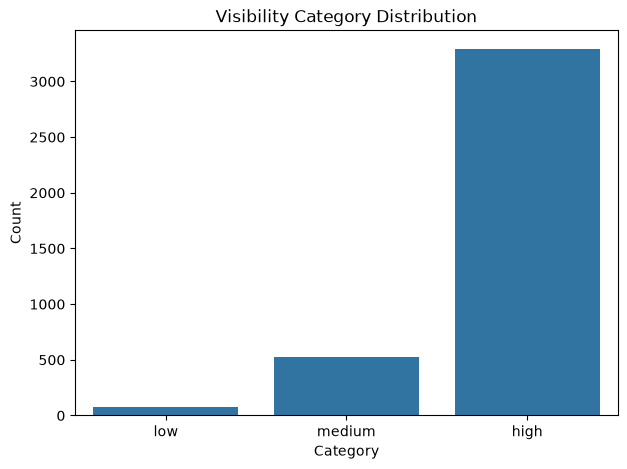

In [68]:
plt.figure(figsize=(7,5))

sns.countplot(x='visibility_category', data=data_df, order=['low', 'medium', 'high'])
plt.title('Visibility Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')

plt.show()

# 7. Data Splitting

## 7.1 Time-Based Train-Test Split

Pembagian data dilakukan berdasarkan urutan waktu (time-based split), bukan pembagian acak (random split), mengingat karakteristik data time series pada penelitian ini. Pembagian acak berisiko menimbulkan kebocoran data (data leakage), khususnya karena keberadaan fitur lag yang bergantung pada urutan temporal.

Urutkan berdasarkan waktu

In [69]:
data_df = data_df.sort_values('DATE_WIB').reset_index(drop=True)

Split 80% data awal untuk training, dan 20% data akhir untuk testing

In [70]:
split_idx = int(len(data_df) * 0.8)

train_df = data_df.iloc[:split_idx]
test_df = data_df.iloc[split_idx:]

In [71]:
print(f'Total data: {len(data_df)}')
print(f'Train: {len(train_df)} ({train_df['DATE_WIB'].min()} - {train_df['DATE_WIB'].max()})')
print(f'Test: {len(test_df)} ({test_df['DATE_WIB'].min()} - {test_df['DATE_WIB'].max()})')

Total data: 3900
Train: 3120 (2024-01-01 16:00:00 - 2024-11-27 19:00:00)
Test: 780 (2024-11-27 20:00:00 - 2025-01-01 06:00:00)


## 7.2 Check Class Distribution in Train vs Test

Mengingat tingkat class imbalance yang sangat tinggi, khususnya pada kategori low (79 observasi dari total 3900), perlu diperiksa apakah distribusi kelas pada train set dan test set tetap proporsional. Risiko utama pada time-based split adalah kemungkinan kelas minoritas terkonsentrasi pada satu sisi pembagian saja.

In [72]:
print('Distribusi kelas - Train set:')
print(train_df['visibility_category'].value_counts())
print(train_df['visibility_category'].value_counts(normalize=True)*100)

Distribusi kelas - Train set:
visibility_category
high      2611
medium     438
low         71
Name: count, dtype: int64
visibility_category
high      83.685897
medium    14.038462
low        2.275641
Name: proportion, dtype: float64


In [73]:
print('Distribusi kelas - Test set:')
print(test_df['visibility_category'].value_counts())
print(test_df['visibility_category'].value_counts(normalize=True)*100)

Distribusi kelas - Test set:
visibility_category
high      682
medium     90
low         8
Name: count, dtype: int64
visibility_category
high      87.435897
medium    11.538462
low        1.025641
Name: proportion, dtype: float64


**Catatan:**

Hasil pembagian data menunjukkan bahwa proporsi kelas pada train set dan test set relatif konsisten dengan proporsi keseluruhan dataset, meskipun kategori low pada test set hanya terdiri dari 8 observasi (1,03% dari 780 data test). Jumlah sampel yang sangat kecil ini merupakan keterbatasan yang perlu diperhatikan dalam interpretasi hasil evaluasi model pada tahap selanjutnya, mengingat metrik seperti recall dan precision untuk kategori low akan memiliki varians yang tinggi dan sensitif terhadap kesalahan prediksi pada sedikit observasi.

# 8. Handling Class Imbalance

Mengingat tingkat class imbalance yang sangat tinggi pada variabel target, khususnya kategori low yang hanya mencakup sekitar 2% dari keseluruhan data, diperlukan strategi penanganan agar model tidak bias terhadap kelas mayoritas (high). Pendekatan yang digunakan pada tahap ini adalah pembobotan kelas (class weighting), yang diterapkan langsung pada masing-masing algoritma tanpa mengubah komposisi data asli melalui teknik oversampling atau undersampling.

## 8.1 Define Feature Columns and Target

Sebelum penerapan pembobotan kelas, ditentukan terlebih dahulu variabel-variabel yang akan digunakan sebagai fitur prediktor (X) dan variabel target (y), berdasarkan seluruh proses feature engineering yang telah dilakukan pada Tahap 5.

In [74]:
feature_cols = [
    'temp_c', 'dewpoint_c', 'wind_speed', 'pressure_hpa', 'precip_mm',
    'wind_dir_sin', 'wind_dir_cos',
    'dewpoint_depression',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'is_fog_prone_hour',
    'visibility_lag1', 'visibility_lag2', 'visibility_lag3'
]

In [75]:
X_train = train_df[feature_cols]
y_train = train_df['visibility_category']

X_test = test_df[feature_cols]
y_test = test_df['visibility_category']

print(f'Jumlah fitur: {len(feature_cols)}')
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')

Jumlah fitur: 16
X_train shape: (3120, 16)
X_test shape: (780, 16)


## 8.2 Calculate Class Weights

Bobot kelas dihitung menggunakan pendekatan balanced, di mana kelas dengan jumlah observasi lebih sedikit (seperti low) akan diberikan bobot yang lebih besar dibandingkan kelas mayoritas (high), sehingga kesalahan prediksi pada kelas minoritas akan lebih "diperhatikan" oleh model selama proses pelatihan.

In [76]:
classes = np.array(['low', 'medium', 'high'])
weight = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)

class_weight_dict = dict(zip(classes, weight))

print('Class weight:')
for cls, w in class_weight_dict.items():
    print(f'{cls}: {w:.4f}')

Class weight:
low: 14.6479
medium: 2.3744
high: 0.3983


**Catatan:**

Hasil perhitungan menunjukkan bobot kelas low sebesar 14,65, jauh lebih tinggi dibandingkan medium (2,37) dan high (0,40), sesuai dengan proporsi jumlah sampel masing-masing kelas pada train set. Bobot yang tinggi ini diharapkan dapat mendorong model untuk lebih memperhatikan kelas minoritas selama proses pelatihan. Namun, perlu diwaspadai potensi overcorrection, di mana model menjadi terlalu agresif memprediksi kelas low sehingga menurunkan precision, meskipun recall meningkat. Keseimbangan antara precision dan recall untuk kelas low akan menjadi fokus utama pada tahap evaluasi model.

**Precision** = dari yang diprediksi low, berapa % yang benar low?
```
Precision = TP / (TP + FP)
```
> Precision rendah → model sering salah alarm (bilang low padahal bukan)

**Recall** = dari semua yang aslinya low, berapa % berhasil terdeteksi?
```
Recall = TP / (TP + FN)
```
> Recall rendah → model sering kecolongan (ada low asli tapi tidak terdeteksi)

# 9. Baseline Modeling

Tahap ini bertujuan untuk melatih tiga algoritma berbasis pohon keputusan (Random Forest, XGBoost, dan LightGBM) menggunakan parameter default, sebagai baseline sebelum dilakukan penyesuaian (hyperparameter tuning) pada tahap selanjutnya. Ketiga model dilatih dengan memperhitungkan bobot kelas yang telah dihitung pada Tahap 8, mengingat tingkat class imbalance yang signifikan pada variabel target

## 9.1 Train Random Forest (Baseline)

Random Forest dilatih menggunakan parameter class_weight='balanced', yang secara otomatis menerapkan pembobotan kelas berbanding terbalik dengan frekuensi masing-masing kelas pada data latih.

In [77]:
rf_model = RandomForestClassifier(class_weight='balanced', random_state=42)

In [78]:
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [79]:
y_pred_rf = rf_model.predict(X_test)

In [80]:
print('------- RANDOM FOREST - CLASSIFICATION REPORT -------\n')
print(classification_report(y_test, y_pred_rf))

------- RANDOM FOREST - CLASSIFICATION REPORT -------

              precision    recall  f1-score   support

        high       0.96      0.91      0.93       682
         low       0.40      0.25      0.31         8
      medium       0.50      0.74      0.60        90

    accuracy                           0.88       780
   macro avg       0.62      0.63      0.61       780
weighted avg       0.90      0.88      0.89       780



## 9.2 Train XGBoost (Baseline)

XGBoost tidak menyediakan parameter class_weight secara langsung untuk kasus klasifikasi multiclass, sehingga pembobotan diterapkan melalui parameter sample_weight, yang dihitung berdasarkan bobot kelas dari Tahap 8.2 untuk masing-masing observasi pada data latih. Label kategorikal juga perlu dikonversi terlebih dahulu menjadi bentuk numerik karena XGBoost mensyaratkan target dalam format tersebut.

In [81]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

sample_weights = y_train.map(class_weight_dict).values

In [82]:
xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train_enc, sample_weight=sample_weights)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklear

In [83]:
y_pred_xgb_enc = xgb_model.predict(X_test)
y_pred_xgb = le.inverse_transform(y_pred_xgb_enc)

In [84]:
print('---------- XGBOOST - CLASSIFICATION REPORT ----------\n')
print(classification_report(y_test, y_pred_xgb))

---------- XGBOOST - CLASSIFICATION REPORT ----------

              precision    recall  f1-score   support

        high       0.95      0.95      0.95       682
         low       0.22      0.25      0.24         8
      medium       0.59      0.57      0.58        90

    accuracy                           0.90       780
   macro avg       0.58      0.59      0.59       780
weighted avg       0.90      0.90      0.90       780



## 9.3 Train LightGBM (Baseline)

LightGBM dilatih dengan parameter class_weight='balanced', serupa dengan pendekatan pada Random Forest, sebagai perbandingan terhadap penerapan sample_weight pada XGBoost.

In [85]:
lgb_model = lgb.LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1)

In [86]:
lgb_model.fit(X_train, y_train)

,class_weight,'balanced'
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,min_split_gain,0.0


In [87]:
y_pred_lgb = lgb_model.predict(X_test)

In [88]:
print('---------- LIGHTGBM - CLASSIFICATION REPORT ----------\n')
print(classification_report(y_test, y_pred_lgb))

---------- LIGHTGBM - CLASSIFICATION REPORT ----------

              precision    recall  f1-score   support

        high       0.96      0.94      0.95       682
         low       0.25      0.25      0.25         8
      medium       0.58      0.70      0.64        90

    accuracy                           0.90       780
   macro avg       0.60      0.63      0.61       780
weighted avg       0.91      0.90      0.91       780



## 9.4 Baseline Comparison Summary

Ketiga model menunjukkan akurasi keseluruhan yang tinggi (88–90%), namun angka ini menyesatkan mengingat dominasi kelas high pada data. Fokus evaluasi diarahkan pada performa kelas low, di mana Random Forest mencatatkan F1-score tertinggi (0,31), diikuti LightGBM (0,25) dan XGBoost (0,24). Seluruh model menunjukkan recall kelas low yang identik (0,25), mengindikasikan kesulitan yang konsisten dalam mendeteksi kejadian visibility rendah. Mengingat jumlah sampel kelas low pada test set yang sangat kecil (8 observasi), perbedaan performa antar model ini perlu diinterpretasikan dengan hati-hati, karena berpotensi tidak signifikan secara statistik. Pada kelas medium, LightGBM menunjukkan performa terbaik (F1-score 0,64) dibandingkan Random Forest (0,60) dan XGBoost (0,58).

# 10. Hyperparameter Tuning (Random Forest)

Random Forest dipilih sebagai model utama untuk dilakukan penyesuaian hyperparameter, mengingat performa awalnya yang paling unggul pada kelas low (F1-score 0,31) dibandingkan XGBoost dan LightGBM pada tahap baseline. Proses tuning bertujuan untuk mengoptimalkan performa model, khususnya dalam mendeteksi kejadian visibility rendah, tanpa mengorbankan performa pada kelas lain secara berlebihan.

## 10.1 Confusion Matrix Baseline Random Forest (Sebelum Tuning)

Sebelum melakukan tuning, confusion matrix diperiksa terlebih dahulu untuk memahami pola kesalahan model secara lebih rinci, khususnya untuk mengetahui kelas mana yang paling sering tertukar dengan kelas low.

In [89]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=['low', 'medium', 'high'])
cm_rf_df = pd.DataFrame(cm_rf, index=['actual_low', 'actual_medium', 'actual_high'],
                       columns=['pred_low', 'pred_medium', 'pred_high'])

cm_rf_df

,pred_low,pred_medium,pred_high
actual_low,2,4,2
actual_medium,2,67,21
actual_high,1,63,618


**Catatan**

Confusion matrix baseline Random Forest menunjukkan bahwa dari 8 kejadian low-visibility yang sebenarnya, 2 kejadian salah diklasifikasikan sebagai high — kesalahan yang paling kritis secara operasional, karena sistem akan mengindikasikan kondisi aman padahal kondisi sebenarnya berbahaya. Sebanyak 4 kejadian salah diklasifikasikan sebagai medium (kesalahan yang lebih dapat ditoleransi), dan hanya 2 kejadian yang terklasifikasi dengan benar. Temuan ini mengarahkan fokus tahap tuning tidak hanya pada peningkatan recall kelas low secara umum, tetapi lebih spesifik pada pengurangan kesalahan klasifikasi low menjadi high.

## 10.2 Hyperparameter Tuning with GridSearchCV

Pencarian kombinasi hyperparameter terbaik dilakukan menggunakan GridSearchCV dengan metrik evaluasi F1-score khusus kelas low, mengingat prioritas utama penelitian ini adalah meminimalkan kesalahan deteksi pada kejadian visibility rendah. Proses cross-validation dilakukan menggunakan TimeSeriesSplit untuk menjaga urutan temporal data selama pembagian fold, konsisten dengan pendekatan time-based split yang digunakan pada tahap sebelumnya.

**Custom Scorer**: fokus ke F1-Score kelas 'low'

In [90]:
f1_low_scorer = make_scorer(f1_score, labels=['low'], average='macro')

**Parameter Grid untuk Random Forest**

In [91]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

**TimeSeriesSplit untuk menjaga urutan waktu saat cross-validation**

In [92]:
tscv = TimeSeriesSplit(n_splits=5)

In [93]:
rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring=f1_low_scorer,
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

In [94]:
rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...average=macro)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more abo

In [95]:
print('Best Parameter: ', rf_grid.best_params_)
print('Best F1-score (low class, cross_validation): ', rf_grid.best_score_)

Best Parameter:  {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Best F1-score (low class, cross_validation):  0.19314574314574315


## 10.3 Evaluate Tuned Model on Test Set

Model dengan kombinasi parameter terbaik hasil pencarian grid dievaluasi kembali pada test set yang sama dengan baseline, guna memastikan perbandingan yang adil (apple-to-apple) antara performa sebelum dan sesudah tuning.

In [96]:
best_rf = rf_grid.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)

In [97]:
print('---- RANDOM FOREST (TUNED) - CLASSIFICATION REPORT ----\n')
print(classification_report(y_test, y_pred_rf_tuned))

---- RANDOM FOREST (TUNED) - CLASSIFICATION REPORT ----

              precision    recall  f1-score   support

        high       0.98      0.80      0.88       682
         low       0.17      0.50      0.26         8
      medium       0.33      0.73      0.46        90

    accuracy                           0.79       780
   macro avg       0.50      0.68      0.53       780
weighted avg       0.90      0.79      0.83       780



In [98]:
print('--------- CONFUSION MATRIX (TUNED) ---------')
cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned, labels=['low', 'medium', 'high'])
cm_rf_tuned_df = pd.DataFrame(
    cm_rf_tuned,
    index=['actual_low', 'actual_medium', 'actual_high'],
    columns=['pred_low', 'pred_medium', 'pred_high']
)
cm_rf_tuned_df

--------- CONFUSION MATRIX (TUNED) ---------


,pred_low,pred_medium,pred_high
actual_low,4,4,0
actual_medium,13,66,11
actual_high,6,129,547


**Catatan:**

Model hasil tuning menunjukkan penurunan akurasi keseluruhan (0,88 menjadi 0,79) dan penurunan tipis F1-score kelas low (0,31 menjadi 0,26), namun mencatatkan perbaikan yang signifikan secara operasional: recall kelas low meningkat dua kali lipat (dari 2 menjadi 4 dari 8 kejadian terdeteksi dengan benar), dan yang terpenting, kesalahan klasifikasi low menjadi high — yang diidentifikasi sebagai kesalahan paling kritis pada Tahap 10.1 — berhasil dihilangkan sepenuhnya (dari 2 kejadian menjadi 0). Seluruh kesalahan pada kelas low kini teralihkan menjadi medium, kesalahan yang secara operasional jauh lebih dapat ditoleransi. Konsekuensinya, precision kelas low menurun tajam (0,40 menjadi 0,17) akibat meningkatnya jumlah false alarm, serta recall kelas high yang menurun (0,91 menjadi 0,80). Trade-off ini mencerminkan keputusan berorientasi keselamatan (safety-oriented), di mana risiko false alarm dianggap lebih dapat diterima dibandingkan risiko kejadian visibility rendah yang terlewat terdeteksi sebagai kondisi aman.

# 11. Feature Importance and Interpretation

Tahap ini bertujuan untuk mengidentifikasi variabel-variabel yang paling berkontribusi terhadap keputusan model dalam mengklasifikasikan kategori visibility. Analisis ini penting untuk menghubungkan hasil pemodelan dengan pengetahuan operasional forecaster, sekaligus memberikan kuantifikasi objektif terhadap pola-pola yang selama ini diketahui secara empiris di lapangan.

## 11.1 Extract Feature Importance from Tuned Model

In [99]:
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': best_rf.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

print(importance_df)

                feature  importance
0   dewpoint_depression    0.269785
1                temp_c    0.158635
2       visibility_lag1    0.139343
3              hour_sin    0.076121
4             precip_mm    0.073915
5     is_fog_prone_hour    0.048906
6              hour_cos    0.046735
7       visibility_lag2    0.032682
8            dewpoint_c    0.029353
9            wind_speed    0.024841
10         pressure_hpa    0.023407
11         wind_dir_cos    0.022862
12      visibility_lag3    0.017837
13            month_sin    0.014969
14         wind_dir_sin    0.013785
15            month_cos    0.006824


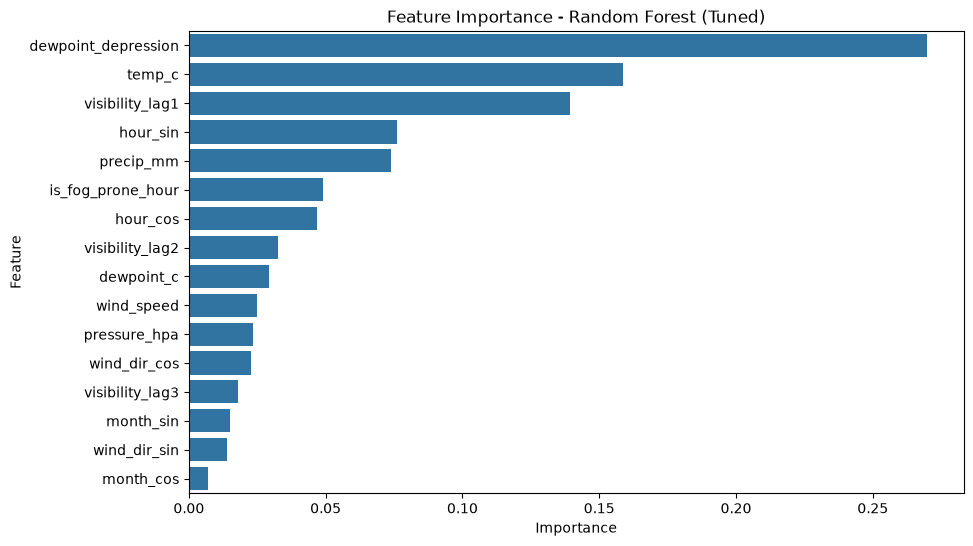

In [100]:
plt.figure(figsize=(10,6))

sns.barplot(x='importance', y='feature', data=importance_df)
plt.title('Feature Importance - Random Forest (Tuned)')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

**Catatan:**

Hasil feature importance menunjukkan bahwa dewpoint_depression merupakan variabel paling berpengaruh (0,270), diikuti oleh temp_c (0,159) dan visibility_lag1 (0,139), dengan ketiganya menyumbang sekitar 57% dari total importance. Temuan yang paling signifikan adalah perbedaan tajam antara dewpoint_depression (fitur turunan, rank pertama) dengan dewpoint_c (variabel mentah, rank kedelapan dengan importance hanya 0,029), yang menjadi bukti kuantitatif konkret bahwa proses rekayasa fitur pada Tahap 5 secara substansial meningkatkan kemampuan model dalam mengenali pola pembentukan kabut. Hasil ini juga mengonfirmasi bahwa pengetahuan operasional forecaster mengenai hubungan antara suhu udara, titik embun, dan visibility dapat dikuantifikasi secara eksplisit melalui pendekatan machine learning. Fitur cyclic bulanan (month_sin, month_cos) menempati peringkat terendah, konsisten dengan pola musiman yang kurang jelas teramati pada tahap eksplorasi data, kemungkinan dipengaruhi oleh keterbatasan cakupan data akibat jeda waktu 14 hari yang teridentifikasi pada Tahap 1.